# Deep Learning and Transformer for Malaysian Stock Price Prediction
 by MD. ZIHADUL AHSAN RATUL

## Project Information

**Project Title:** Deep Learning and Transformer for Malaysian Stock Price Prediction

**Problem Type:** Time Series Forecasting using Deep Learning

**Dataset Source:** Yahoo Finance (yfinance)

**Selected Bursa Malaysia Stocks:**

| Company | Sector | Ticker |
|---|---|---|
| Maybank | Banking | 1155.KL |
| Petronas Gas | Energy | 6033.KL |
| IHH Healthcare | Healthcare | 5225.KL |
| Mr. D.I.Y. Group | Consumer Retail | 5296.KL |

**Study Period:** 1 January 2015 – 30 June 2026

**Development Platform:** Google Colab (Python)

---

## Deep Learning Models

The following deep learning models are implemented and compared in this project:

- Long Short-Term Memory (LSTM)
- Gated Recurrent Unit (GRU)
- Transformer

---

## Project Objectives

The objectives of this project are:

1. To collect and preprocess historical stock market data from Bursa Malaysia.
2. To perform exploratory data analysis (EDA) and feature engineering using technical indicators.
3. To develop LSTM, GRU, and Transformer models for stock price prediction.
4. To compare the performance of the three deep learning models using MAE, RMSE, MAPE, R² Score, and Directional Accuracy.
5. To analyze the performance of the models under different market regimes (Bull, Bear, and Sideways).
6. To identify the most effective deep learning model for Malaysian stock price forecasting.

##Install Required Libraries

In [ ]:
!pip install yfinance ta

#Import Required Libraries



In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import yfinance as yf

from ta.trend import SMAIndicator
from ta.trend import MACD
from ta.momentum import RSIIndicator
from ta.volatility import BollingerBands

from sklearn.preprocessing import MinMaxScaler

print("All libraries imported successfully!")

# Download Historical Stock Data

In [ ]:
stocks = {
    "Maybank": "1155.KL",
    "Petronas Gas": "6033.KL",
    "IHH Healthcare": "5225.KL",
    "MrDIY": "5296.KL"
}

datasets = {}

for company, ticker in stocks.items():

    df = yf.download(
        ticker,
        start="2015-01-01",
        end="2026-06-30",
        progress=False,
        auto_adjust=False
    )

    # Fix MultiIndex (latest yfinance)
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)

    # Make Date a normal column
    df = df.reset_index()

    datasets[company] = df

print("All stock datasets downloaded successfully!")

#Verify the Downloaded Datasets

In [ ]:
for company, df in datasets.items():

    print("=" * 60)
    print(company)
    print("=" * 60)

    display(df.head())

# Data Preprocessing

In [ ]:
# Remove the extra column index name ("Price")

for df in datasets.values():
    df.columns.name = None

print("Column index names removed successfully.")

In [ ]:
# Check dataset dimensions

for company, df in datasets.items():
    print(f"{company}: {df.shape}")

In [ ]:
# Display dataset information

for company, df in datasets.items():

    print("="*60)
    print(company)
    print("="*60)

    df.info()

    print()

In [ ]:
# Check missing values

for company, df in datasets.items():

    print("="*60)
    print(company)
    print("="*60)

    print(df.isnull().sum())

    print()

In [ ]:
# Clean each dataset

for df in datasets.values():

    # Remove missing values
    df.dropna(inplace=True)

    # Convert Date column
    df["Date"] = pd.to_datetime(df["Date"])

    # Sort by date
    df.sort_values("Date", inplace=True)

    # Reset index
    df.reset_index(drop=True, inplace=True)

print("All datasets cleaned successfully.")

In [ ]:
# Verify cleaned datasets

for company, df in datasets.items():

    print("="*60)
    print(company)
    print("="*60)

    display(df.head())

# Exploratory Data Analysis (EDA)

## Descriptive Statistics

In [ ]:
for company, df in datasets.items():

    print("="*70)
    print(company)
    print("="*70)

    display(df.describe())

## Closing Price Trend

In [ ]:
plt.figure(figsize=(15,6))

for company, df in datasets.items():
    plt.plot(df["Date"], df["Close"], label=company)

plt.title("Closing Price Comparison")
plt.xlabel("Date")
plt.ylabel("Closing Price (RM)")
plt.legend()
plt.grid(True)

plt.show()

## Trading Volume

In [ ]:
plt.figure(figsize=(15,6))

for company, df in datasets.items():
    plt.plot(df["Date"], df["Volume"], label=company)

plt.title("Trading Volume Comparison")
plt.xlabel("Date")
plt.ylabel("Volume")

plt.legend()
plt.grid(True)

plt.show()

## Closing Price Distribution

In [ ]:
for company, df in datasets.items():

    plt.figure(figsize=(8,5))

    plt.hist(df["Close"], bins=30)

    plt.title(f"{company} Closing Price Distribution")

    plt.xlabel("Closing Price")

    plt.ylabel("Frequency")

    plt.grid(True)

    plt.show()

## Correlation Matrix

In [ ]:
for company, df in datasets.items():

    plt.figure(figsize=(8,6))

    correlation = df.drop(columns=["Date"]).corr()

    plt.imshow(correlation)

    plt.colorbar()

    plt.xticks(
        range(len(correlation.columns)),
        correlation.columns,
        rotation=45
    )

    plt.yticks(
        range(len(correlation.columns)),
        correlation.columns
    )

    plt.title(f"{company} Correlation Matrix")

    plt.tight_layout()

    plt.show()

#  Feature Engineering

## Generate Technical Indicators

In [ ]:
import matplotlib.pyplot as plt

features = ["Close", "Volume", "SMA10", "RSI14", "MACD"]

maybank_df = datasets["Maybank"]

maybank_df[features].hist(figsize=(12, 8))

plt.suptitle("Feature Distribution - Maybank")
plt.tight_layout()
plt.show()

In [ ]:
for company, df in datasets.items():

    # ===========================
    # Simple Moving Average
    # ===========================

    df["SMA10"] = SMAIndicator(
        close=df["Close"],
        window=10
    ).sma_indicator()

    df["SMA50"] = SMAIndicator(
        close=df["Close"],
        window=50
    ).sma_indicator()

    # ===========================
    # RSI
    # ===========================

    df["RSI14"] = RSIIndicator(
        close=df["Close"],
        window=14
    ).rsi()

    # ===========================
    # MACD
    # ===========================

    macd = MACD(close=df["Close"])

    df["MACD"] = macd.macd()

    df["MACD_Signal"] = macd.macd_signal()

    # ===========================
    # Bollinger Bands
    # ===========================

    bollinger = BollingerBands(
        close=df["Close"],
        window=20,
        window_dev=2
    )

    df["BB_Upper"] = bollinger.bollinger_hband()

    df["BB_Middle"] = bollinger.bollinger_mavg()

    df["BB_Lower"] = bollinger.bollinger_lband()

print("Technical Indicators Generated Successfully!")

## Display the Newly Generated Features

In [ ]:
for company, df in datasets.items():

    print("="*70)
    print(company)
    print("="*70)

    display(
        df[
            [
                "Date",
                "Close",
                "SMA10",
                "SMA50",
                "RSI14",
                "MACD",
                "MACD_Signal",
                "BB_Upper",
                "BB_Middle",
                "BB_Lower"
            ]
        ].tail()
    )

## Check Missing Values After Feature Engineering

In [ ]:
for company, df in datasets.items():

    print("="*70)
    print(company)
    print("="*70)

    print(df.isnull().sum())

    print()

## Remove Missing Values

In [ ]:
for df in datasets.values():

    df.dropna(inplace=True)

    df.reset_index(drop=True, inplace=True)

print("Missing values removed successfully.")

## Verify the Final Dataset

In [ ]:
for company, df in datasets.items():

    print("="*70)
    print(company)
    print("="*70)

    display(df.head())

#  Data Normalization

## Select Features for Model Training

In [ ]:
FEATURES = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "SMA10",
    "SMA50",
    "RSI14",
    "MACD",
    "MACD_Signal",
    "BB_Upper",
    "BB_Middle",
    "BB_Lower"
]

TARGET = "Close"

print("Number of Input Features:", len(FEATURES))
print(FEATURES)

## Apply Min-Max Normalization

In [ ]:
normalized_datasets = {}
scalers = {}

for company, df in datasets.items():

    scaler = MinMaxScaler()

    normalized_data = scaler.fit_transform(df[FEATURES])

    normalized_df = pd.DataFrame(
        normalized_data,
        columns=FEATURES
    )

    normalized_df["Date"] = df["Date"].values

    normalized_datasets[company] = normalized_df

    scalers[company] = scaler

print("Normalization Completed Successfully!")

## Verify the Normalized Dataset

In [ ]:
for company, df in normalized_datasets.items():

    print("="*70)
    print(company)
    print("="*70)

    display(df.head())

## Verify Feature Ranges

In [ ]:
for company, df in normalized_datasets.items():

    print("="*70)
    print(company)
    print("="*70)

    print(df[FEATURES].agg(["min", "max"]))
    print()

#Sequence Generation (Sliding Window)

## Define Sliding Window Size

In [ ]:
WINDOW_SIZE = 60

print("Window Size:", WINDOW_SIZE)

## Create Time-Series Sequences

In [ ]:
def create_sequences(data, window_size=60):

    X = []
    y = []

    values = data[FEATURES].values
    target = data[TARGET].values

    for i in range(window_size, len(data)):

        X.append(values[i-window_size:i])

        y.append(target[i])

    return np.array(X), np.array(y)

## Generate Sequences for All Companies

In [ ]:
sequence_data = {}

for company, df in normalized_datasets.items():

    X, y = create_sequences(df, WINDOW_SIZE)

    sequence_data[company] = {
        "X": X,
        "y": y
    }

print("Sequence generation completed successfully!")

## Display Dataset Shapes

In [ ]:
for company, data in sequence_data.items():

    print("=" * 60)
    print(company)

    print("X Shape :", data["X"].shape)
    print("y Shape :", data["y"].shape)

    print()

## Inspect One Sample

In [ ]:
company = "Maybank"

print("Input Shape :", sequence_data[company]["X"][0].shape)
print("Target Value :", sequence_data[company]["y"][0])

# Train, Validation and Test Split

In [ ]:
def chronological_split(X, y):

    total = len(X)

    train_end = int(total * 0.70)
    val_end = int(total * 0.80)

    X_train = X[:train_end]
    y_train = y[:train_end]

    X_val = X[train_end:val_end]
    y_val = y[train_end:val_end]

    X_test = X[val_end:]
    y_test = y[val_end:]

    return X_train, X_val, X_test, y_train, y_val, y_test

## Apply the Data Split

In [ ]:
split_data = {}

for company, data in sequence_data.items():

    X_train, X_val, X_test, y_train, y_val, y_test = chronological_split(
        data["X"],
        data["y"]
    )

    split_data[company] = {

        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,

        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }

print("Train/Validation/Test Split Completed Successfully!")

## Display Dataset Sizes

In [ ]:
for company, data in split_data.items():

    print("="*60)
    print(company)
    print("="*60)

    print("Training :", data["X_train"].shape)

    print("Validation :", data["X_val"].shape)

    print("Testing :", data["X_test"].shape)

    print()

## Verify Target Sizes

In [ ]:
for company, data in split_data.items():

    print("="*60)
    print(company)
    print("="*60)

    print("Training Labels :", data["y_train"].shape)

    print("Validation Labels :", data["y_val"].shape)

    print("Testing Labels :", data["y_test"].shape)

    print()

#  Deep Learning Model Development

## Import Deep Learning Libraries

In [ ]:
import tensorflow as tf

from tensorflow.keras.models import Sequential, Model

from tensorflow.keras.layers import (
    LSTM,
    GRU,
    Dense,
    Dropout,
    Input,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D,
    Add
)

from tensorflow.keras.callbacks import EarlyStopping

from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("TensorFlow Version:", tf.__version__)

## Configure Training Parameters

In [ ]:
EPOCHS = 100
BATCH_SIZE = 32
LEARNING_RATE = 0.001

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

print("Training configuration completed.")

## Define Evaluation Metrics

In [ ]:
def directional_accuracy(y_true, y_pred):

    true_direction = np.sign(np.diff(y_true))

    pred_direction = np.sign(np.diff(y_pred))

    return np.mean(true_direction == pred_direction) * 100


def evaluate_model(y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    r2 = r2_score(y_true, y_pred)

    da = directional_accuracy(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2,
        "DA": da
    }

print("Evaluation functions created.")

## Create Results Storage

In [ ]:
trained_models = {}

results = []

# Long Short-Term Memory (LSTM) Model

## Build the LSTM Model

In [ ]:
def build_lstm_model(input_shape):

    model = Sequential([

        LSTM(
            units=64,
            return_sequences=True,
            input_shape=input_shape
        ),

        Dropout(0.2),

        LSTM(
            units=64
        ),

        Dropout(0.2),

        Dense(1)

    ])

    model.compile(

        optimizer=Adam(learning_rate=LEARNING_RATE),

        loss="mse"

    )

    return model

## Display the Model Architecture

In [ ]:
sample_company = "Maybank"

input_shape = (
    split_data[sample_company]["X_train"].shape[1],
    split_data[sample_company]["X_train"].shape[2]
)

lstm_model = build_lstm_model(input_shape)

lstm_model.summary()

## Train the LSTM Model

In [ ]:
lstm_histories = {}

lstm_models = {}

for company, data in split_data.items():

    print("="*70)
    print(f"Training LSTM for {company}")
    print("="*70)

    model = build_lstm_model(

        (
            data["X_train"].shape[1],
            data["X_train"].shape[2]
        )

    )

    history = model.fit(

        data["X_train"],
        data["y_train"],

        validation_data=(
            data["X_val"],
            data["y_val"]
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[early_stop],

        verbose=1

    )

    lstm_histories[company] = history

    lstm_models[company] = model

Training LSTM for Maybank
Epoch 1/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - loss: 0.0047 - val_loss: 2.9150e-04
Epoch 2/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 73ms/step - loss: 0.0018 - val_loss: 3.2136e-04
Epoch 3/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 66ms/step - loss: 0.0018 - val_loss: 3.0388e-04
Epoch 4/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 87ms/step - loss: 0.0015 - val_loss: 3.1025e-04
Epoch 5/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - loss: 0.0015 - val_loss: 2.7549e-04
Epoch 6/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0015 - val_loss: 2.3950e-04
Epoch 7/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 9s 154ms/step - loss: 0.0015 - val_loss: 2.3510e-04
Epoch 8/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 99ms/step - loss: 0.0012 - val_loss: 4.9168e-04
Epoch 9/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - loss: 0.0013 - val_loss: 2.2386e-04
Epoch 10/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 9s 156ms/step - loss: 0.0012 - val_loss: 2.3221e-04
Epoch 11/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 92ms/step - loss: 0.0012 - 

## Plot the Training History

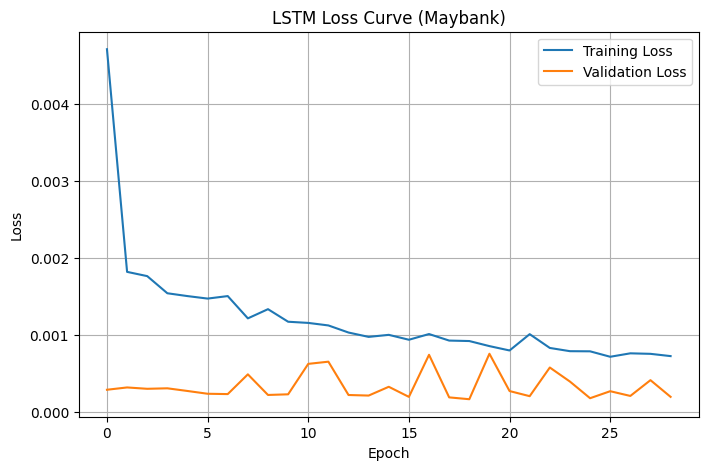

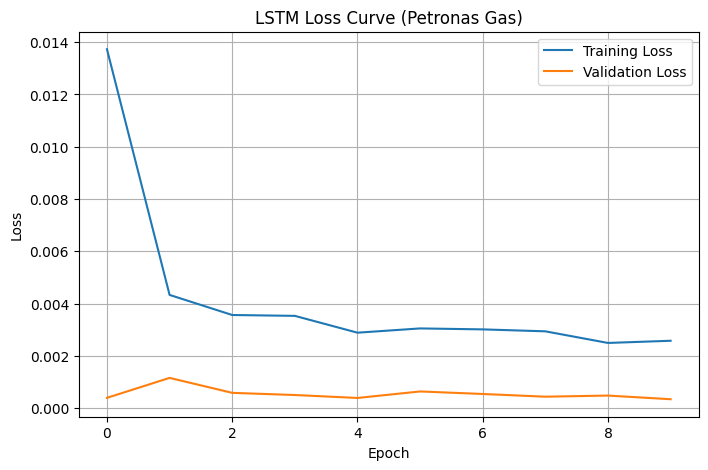

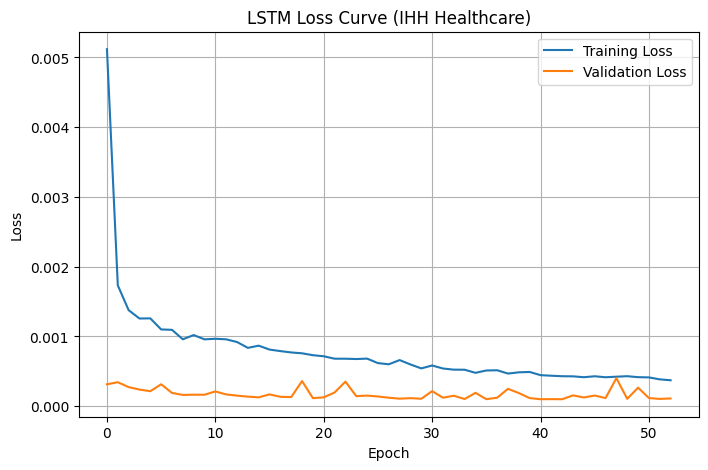

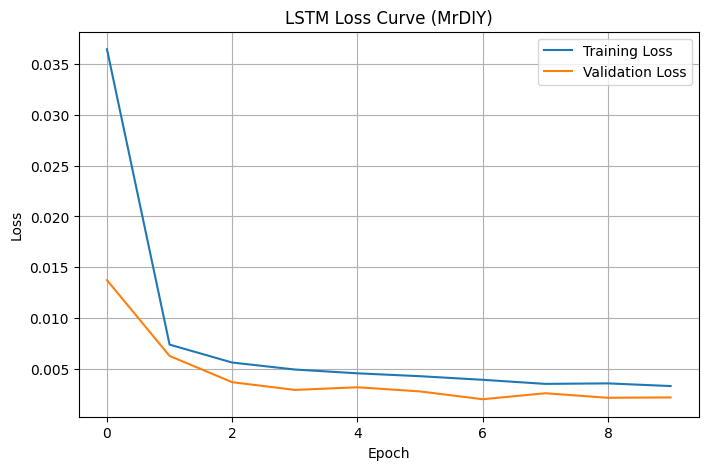

In [ ]:
for company, history in lstm_histories.items():

    plt.figure(figsize=(8,5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.title(f"LSTM Loss Curve ({company})")

    plt.xlabel("Epoch")

    plt.ylabel("Loss")

    plt.legend()

    plt.grid(True)

    plt.show()

## Generate Predictions

In [ ]:
lstm_predictions = {}

for company, model in lstm_models.items():

    prediction = model.predict(

        split_data[company]["X_test"],
        verbose=0

    )

    lstm_predictions[company] = prediction.flatten()

print("Predictions generated successfully.")

Predictions generated successfully.


## Evaluate the LSTM Model

In [ ]:
for company in lstm_models.keys():

    metrics = evaluate_model(

        split_data[company]["y_test"],

        lstm_predictions[company]

    )

    results.append({

        "Company": company,

        "Model": "LSTM",

        **metrics

    })

print("LSTM Evaluation Completed.")

LSTM Evaluation Completed.


## Display the Evaluation Results

In [ ]:
lstm_results = pd.DataFrame(results)

display(lstm_results)

,Company,Model,MAE,RMSE,MAPE,R2,DA
0,Maybank,LSTM,0.018133,0.027890,2.689881,0.938885,36.464088
1,Petronas Gas,LSTM,0.025038,0.035502,7.738792,0.646932,39.594843
2,IHH Healthcare,LSTM,0.020927,0.030520,3.089039,0.975067,41.804788
3,MrDIY,LSTM,0.055960,0.068332,30.280542,-0.296199,41.796875


## Visual Comparison

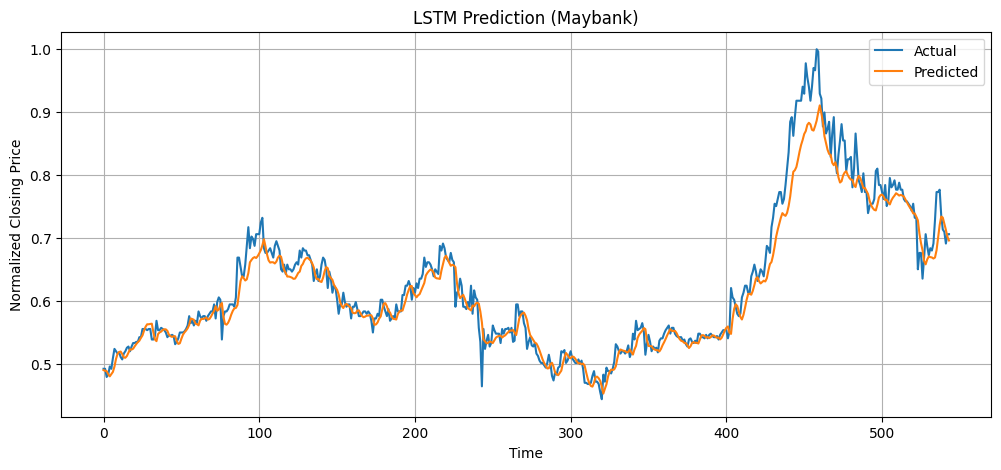

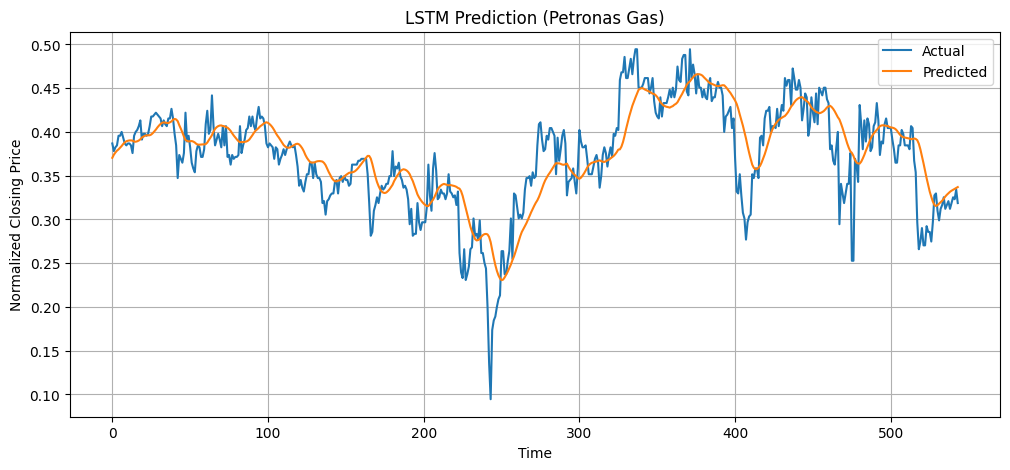

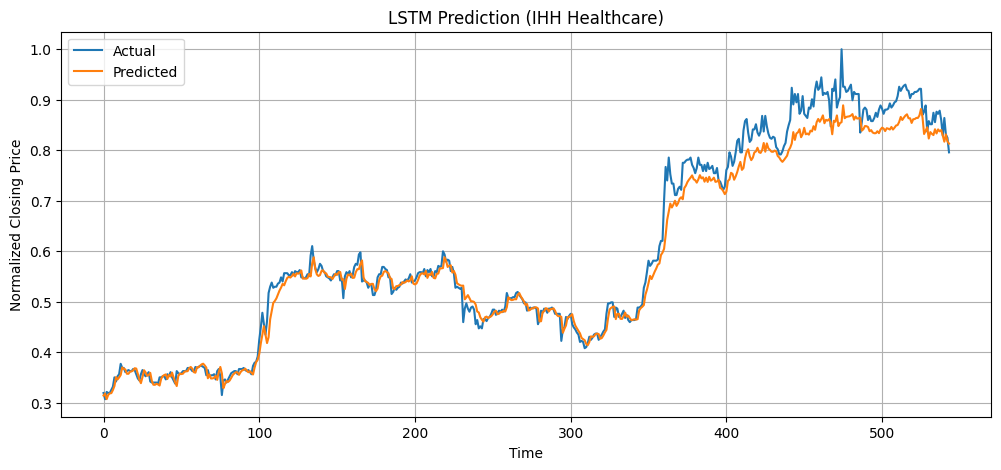

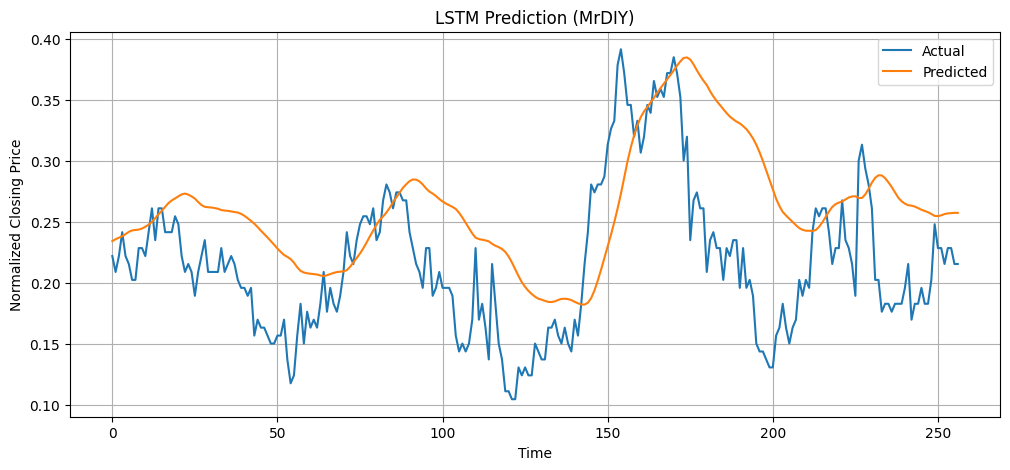

In [ ]:
for company in lstm_models.keys():

    plt.figure(figsize=(12,5))

    plt.plot(

        split_data[company]["y_test"],

        label="Actual"

    )

    plt.plot(

        lstm_predictions[company],

        label="Predicted"

    )

    plt.title(f"LSTM Prediction ({company})")

    plt.xlabel("Time")

    plt.ylabel("Normalized Closing Price")

    plt.legend()

    plt.grid(True)

    plt.show()

# Gated Recurrent Unit (GRU) Model

## Build the GRU Model

In [ ]:
def build_gru_model(input_shape):

    model = Sequential([

        GRU(
            units=64,
            return_sequences=True,
            input_shape=input_shape
        ),

        Dropout(0.2),

        GRU(
            units=64
        ),

        Dropout(0.2),

        Dense(1)

    ])

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="mse"
    )

    return model

## Display the GRU Model Architecture

In [ ]:
sample_company = "Maybank"

input_shape = (
    split_data[sample_company]["X_train"].shape[1],
    split_data[sample_company]["X_train"].shape[2]
)

gru_model = build_gru_model(input_shape)

gru_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 60, 64)         │        15,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 60, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,193 (157.00 KB)

 Trainable params: 40,193 (157.00 KB)

 Non-trainable params: 0 (0.00 B)

## Train the GRU Model

In [ ]:
gru_histories = {}

gru_models = {}

for company, data in split_data.items():

    print("="*70)
    print(f"Training GRU for {company}")
    print("="*70)

    model = build_gru_model(
        (
            data["X_train"].shape[1],
            data["X_train"].shape[2]
        )
    )

    history = model.fit(

        data["X_train"],
        data["y_train"],

        validation_data=(
            data["X_val"],
            data["y_val"]
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[early_stop],

        verbose=1
    )

    gru_histories[company] = history
    gru_models[company] = model

Training GRU for Maybank
Epoch 1/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 10s 86ms/step - loss: 0.0081 - val_loss: 5.6477e-04
Epoch 2/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - loss: 0.0024 - val_loss: 3.9138e-04
Epoch 3/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - loss: 0.0018 - val_loss: 2.4262e-04
Epoch 4/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 99ms/step - loss: 0.0017 - val_loss: 3.8921e-04
Epoch 5/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 79ms/step - loss: 0.0015 - val_loss: 8.2768e-04
Epoch 6/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 7s 106ms/step - loss: 0.0015 - val_loss: 0.0013
Epoch 7/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 9s 83ms/step - loss: 0.0013 - val_loss: 3.0756e-04
Epoch 8/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 105ms/step - loss: 0.0013 - val_loss: 1.3443e-04
Epoch 9/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 5s 85ms/step - loss: 0.0011 - val_loss: 2.8527e-04
Epoch 10/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 6s 102ms/step - loss: 0.0011 - val_loss: 1.8072e-04
Training GRU for Petronas Gas
Epoch 1/100
60/60 ━━━━━━━━━━━━━━━━━━━━ 10s 

## Plot Training and Validation Loss

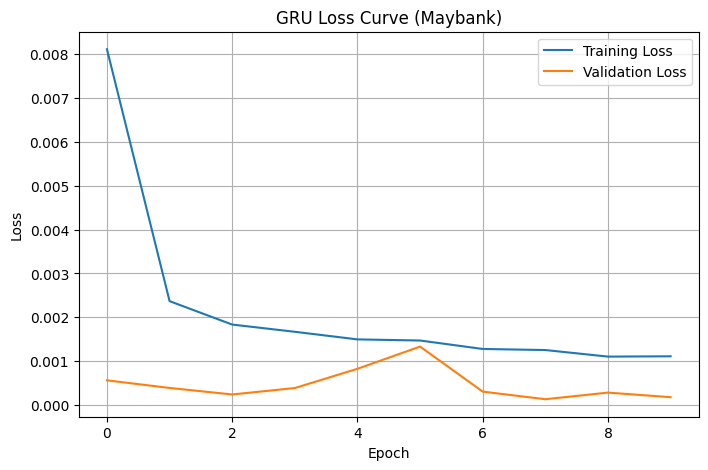

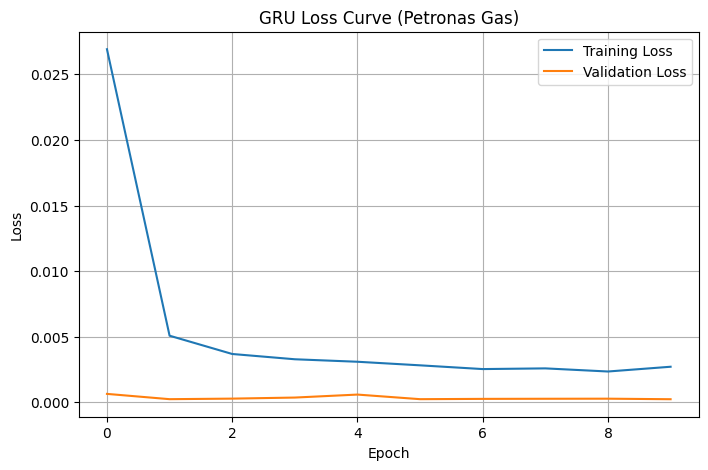

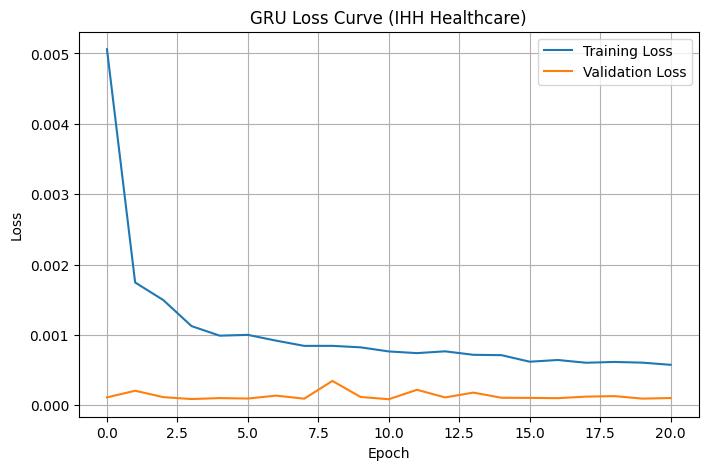

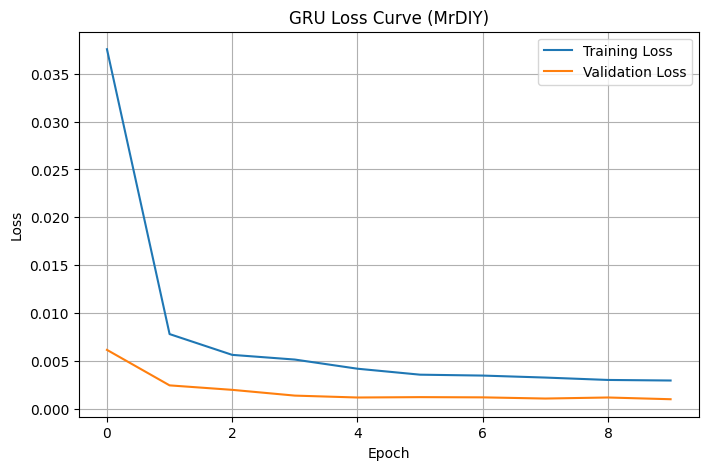

In [ ]:
for company, history in gru_histories.items():

    plt.figure(figsize=(8,5))

    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")

    plt.title(f"GRU Loss Curve ({company})")

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.legend()
    plt.grid(True)

    plt.show()

## Generate Predictions

In [ ]:
gru_predictions = {}

for company, model in gru_models.items():

    prediction = model.predict(
        split_data[company]["X_test"],
        verbose=0
    )

    gru_predictions[company] = prediction.flatten()

print("GRU predictions generated successfully.")

GRU predictions generated successfully.


## Evaluate the GRU Model

In [ ]:
for company in gru_models.keys():

    metrics = evaluate_model(

        split_data[company]["y_test"],
        gru_predictions[company]

    )

    results.append({

        "Company": company,
        "Model": "GRU",

        **metrics

    })

print("GRU Evaluation Completed.")

GRU Evaluation Completed.


## Display GRU Evaluation Results

In [ ]:
results_df = pd.DataFrame(results)

display(results_df)

,Company,Model,MAE,RMSE,MAPE,R2,DA
0,Maybank,LSTM,0.018133,0.027890,2.689881,0.938885,36.464088
1,Petronas Gas,LSTM,0.025038,0.035502,7.738792,0.646932,39.594843
2,IHH Healthcare,LSTM,0.020927,0.030520,3.089039,0.975067,41.804788
3,MrDIY,LSTM,0.055960,0.068332,30.280542,-0.296199,41.796875
4,Maybank,GRU,0.020021,0.027885,3.125835,0.938909,38.121547
5,Petronas Gas,GRU,0.026725,0.035416,7.788903,0.648649,37.384899
6,IHH Healthcare,GRU,0.012385,0.019218,2.070135,0.990114,40.699816
7,MrDIY,GRU,0.052788,0.061832,28.281352,-0.061318,42.187500


## Actual vs Predicted Stock Prices

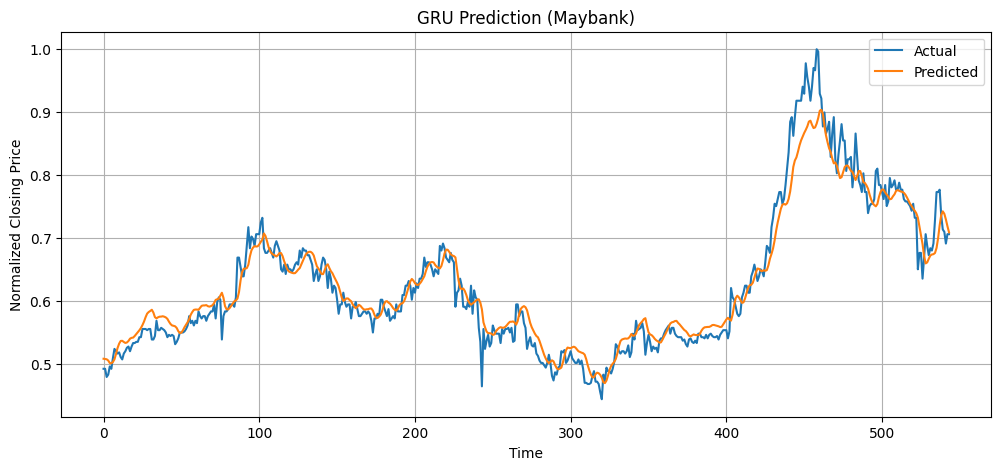

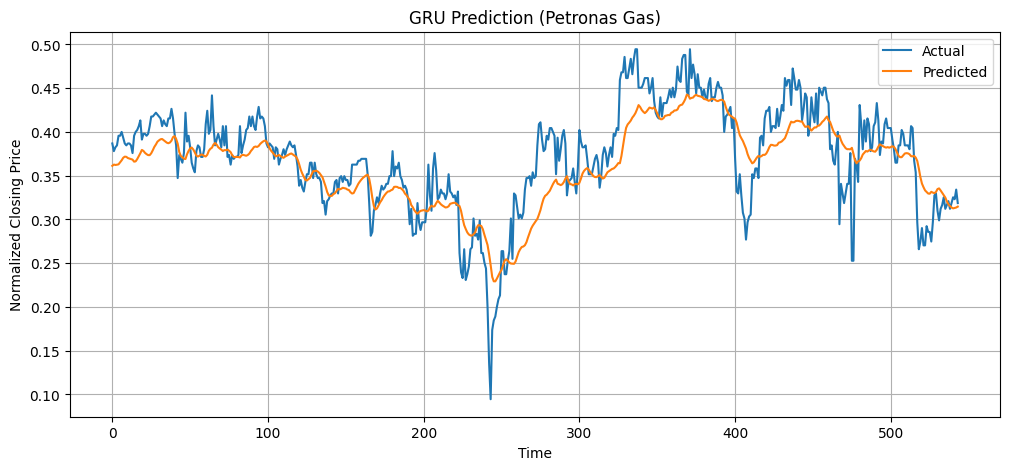

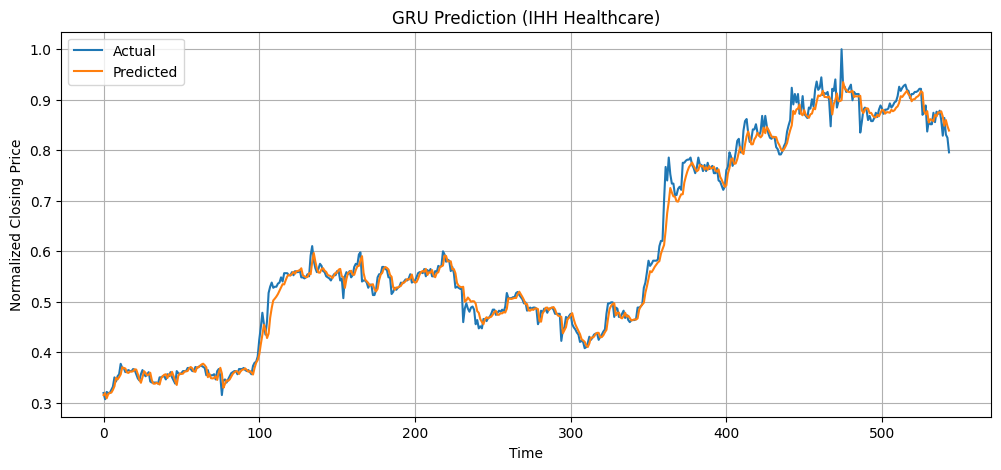

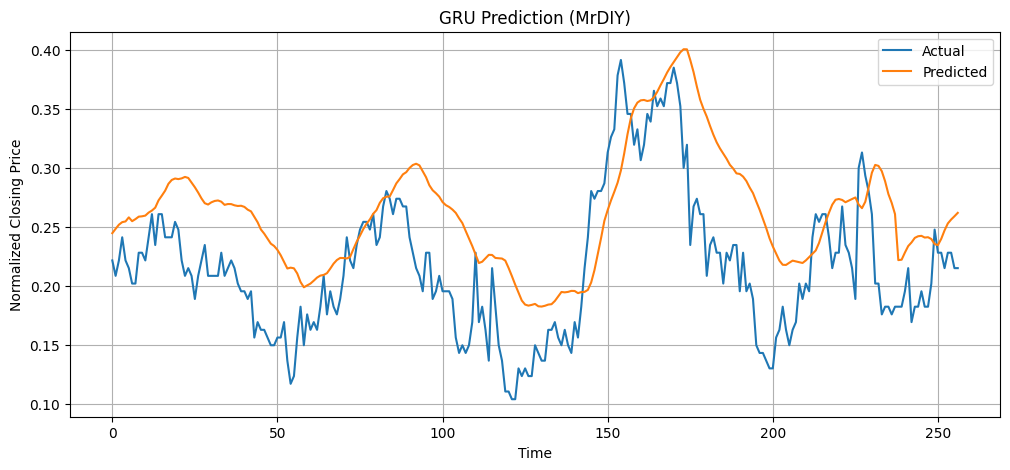

In [ ]:
for company in gru_models.keys():

    plt.figure(figsize=(12,5))

    plt.plot(
        split_data[company]["y_test"],
        label="Actual"
    )

    plt.plot(
        gru_predictions[company],
        label="Predicted"
    )

    plt.title(f"GRU Prediction ({company})")

    plt.xlabel("Time")
    plt.ylabel("Normalized Closing Price")

    plt.legend()
    plt.grid(True)

    plt.show()

#  Transformer Model

## Build Transformer Encoder Block

In [ ]:
def transformer_encoder(inputs, head_size=64, num_heads=4, ff_dim=128, dropout=0.1):

    # Multi-Head Attention
    attention = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=head_size
    )(inputs, inputs)

    attention = Dropout(dropout)(attention)

    x = Add()([inputs, attention])

    x = LayerNormalization(epsilon=1e-6)(x)

    # Feed Forward Network
    ffn = Dense(ff_dim, activation="relu")(x)

    ffn = Dense(inputs.shape[-1])(ffn)

    ffn = Dropout(dropout)(ffn)

    x = Add()([x, ffn])

    x = LayerNormalization(epsilon=1e-6)(x)

    return x

## Build Transformer Model

In [ ]:
def build_transformer_model(input_shape):

    inputs = Input(shape=input_shape)

    x = transformer_encoder(inputs)

    x = transformer_encoder(x)

    x = GlobalAveragePooling1D()(x)

    outputs = Dense(1)(x)

    model = Model(inputs, outputs)

    model.compile(

        optimizer=Adam(learning_rate=LEARNING_RATE),

        loss="mse"

    )

    return model

## Display Transformer Architecture

In [ ]:
sample_company = "Maybank"

input_shape = (
    split_data[sample_company]["X_train"].shape[1],
    split_data[sample_company]["X_train"].shape[2]
)

transformer_model = build_transformer_model(input_shape)

transformer_model.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, 60, 13)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 60, 13)    │     14,093 │ input_layer_10[0… │
│ (MultiHeadAttentio… │                   │            │ input_layer_10[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_21          │ (None, 60, 13)    │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 60, 13)    │          0 │ input_layer_10[0… │
│                     │                   │            │ dropout_21[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 60, 13)    │         26 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 60, 128)   │      1,792 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 60, 13)    │      1,677 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_22          │ (None, 60, 13)    │          0 │ dense_11[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 60, 13)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_22[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 13)    │         26 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 60, 13)    │     14,093 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_24          │ (None, 60, 13)    │          0 │ multi_head_atten… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 60, 13)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_24[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 60, 13)    │         26 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_12 (Dense)    │ (None, 60, 128)   │      1,792 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_13 (Dense)    │ (None, 60, 13)    │      1,677 │ dense_12[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_25          │ (None, 60, 13)    │          0 │ dense_13[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 60, 13)    │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_25[0][0]

 Total params: 35,242 (137.66 KB)

 Trainable params: 35,242 (137.66 KB)

 Non-trainable params: 0 (0.00 B)

## Train Transformer Model

In [ ]:
transformer_histories = {}

transformer_models = {}

for company, data in split_data.items():

    print("="*70)
    print(f"Training Transformer for {company}")
    print("="*70)

    model = build_transformer_model(
        (
            data["X_train"].shape[1],
            data["X_train"].shape[2]
        )
    )

    history = model.fit(

        data["X_train"],
        data["y_train"],

        validation_data=(
            data["X_val"],
            data["y_val"]
        ),

        epochs=EPOCHS,

        batch_size=BATCH_SIZE,

        callbacks=[early_stop],

        verbose=1

    )

    transformer_histories[company] = history

    transformer_models[company] = model

## Plot Training History

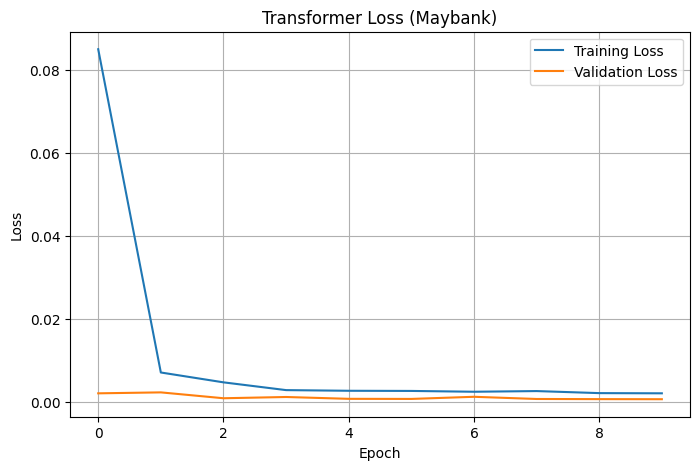

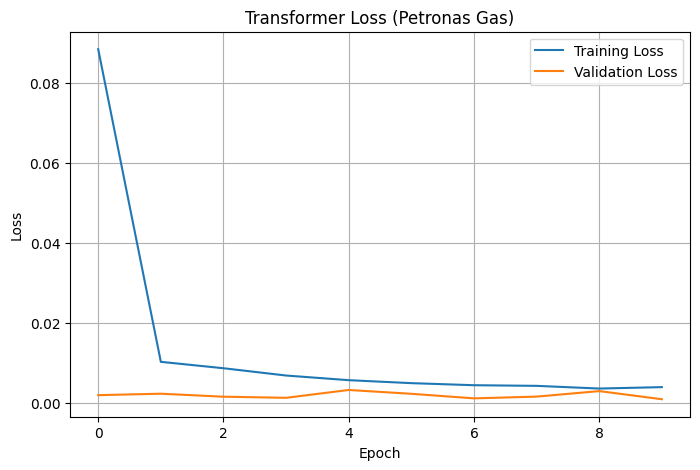

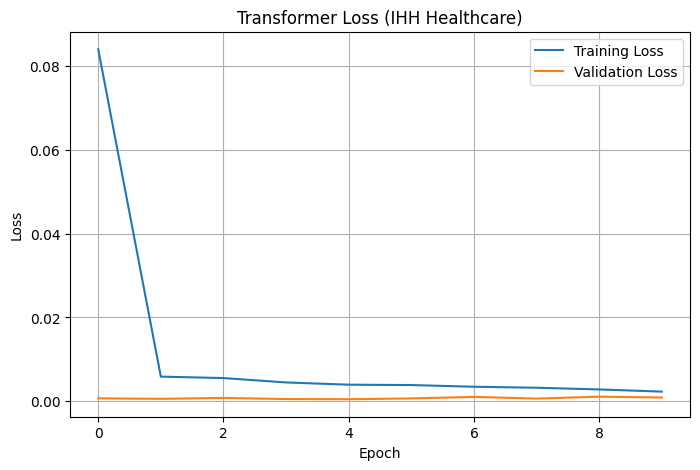

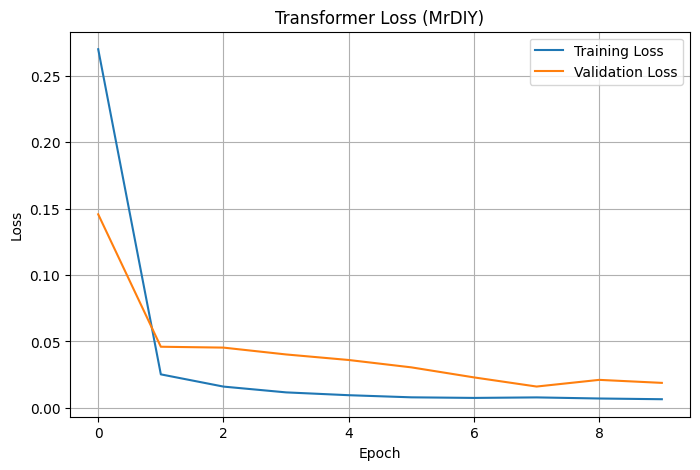

In [ ]:
for company, history in transformer_histories.items():

    plt.figure(figsize=(8,5))

    plt.plot(history.history["loss"], label="Training Loss")

    plt.plot(history.history["val_loss"], label="Validation Loss")

    plt.title(f"Transformer Loss ({company})")

    plt.xlabel("Epoch")

    plt.ylabel("Loss")

    plt.legend()

    plt.grid(True)

    plt.show()

## Generate Predictions

In [ ]:
transformer_predictions = {}

for company, model in transformer_models.items():

    prediction = model.predict(

        split_data[company]["X_test"],

        verbose=0

    )

    transformer_predictions[company] = prediction.flatten()

print("Transformer predictions completed.")

Transformer predictions completed.


## Evaluate Transformer Model

In [ ]:
for company in transformer_models.keys():

    metrics = evaluate_model(

        split_data[company]["y_test"],

        transformer_predictions[company]

    )

    results.append({

        "Company": company,

        "Model": "Transformer",

        **metrics

    })

print("Transformer evaluation completed.")

Transformer evaluation completed.


## Display Evaluation Results

In [ ]:
results_df = pd.DataFrame(results)

display(results_df)

,Company,Model,MAE,RMSE,MAPE,R2,DA
0,Maybank,LSTM,0.018133,0.027890,2.689881,0.938885,36.464088
1,Petronas Gas,LSTM,0.025038,0.035502,7.738792,0.646932,39.594843
2,IHH Healthcare,LSTM,0.020927,0.030520,3.089039,0.975067,41.804788
3,MrDIY,LSTM,0.055960,0.068332,30.280542,-0.296199,41.796875
4,Maybank,GRU,0.020021,0.027885,3.125835,0.938909,38.121547
5,Petronas Gas,GRU,0.026725,0.035416,7.788903,0.648649,37.384899
6,IHH Healthcare,GRU,0.012385,0.019218,2.070135,0.990114,40.699816
7,MrDIY,GRU,0.052788,0.061832,28.281352,-0.061318,42.187500
8,Maybank,Transformer,0.164572,0.198824,24.321295,-2.105843,41.620626
9,Petronas Gas,Transformer,0.064449,0.078471,19.315282,-0.724927,45.856354


## Actual vs Predicted Stock Prices

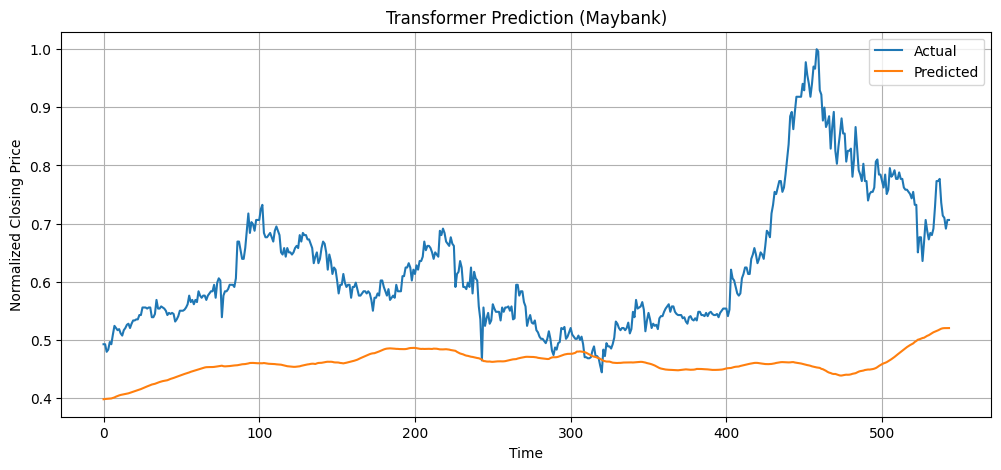

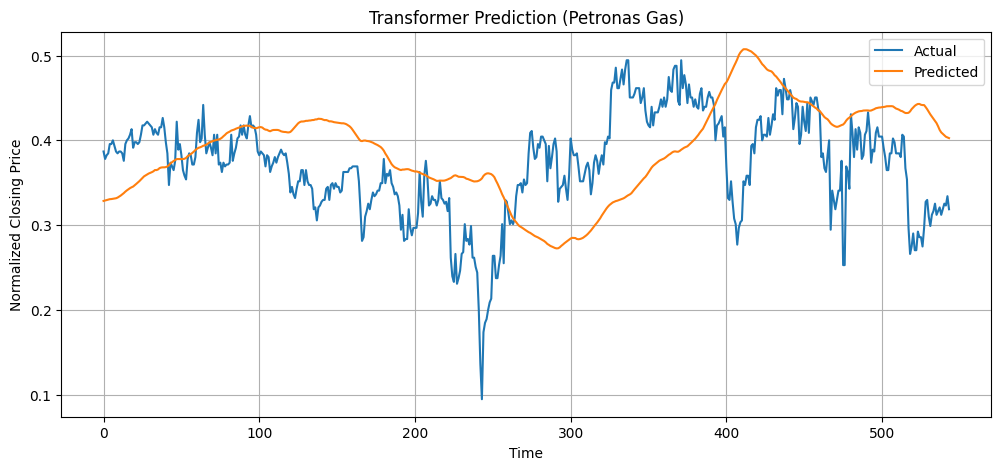

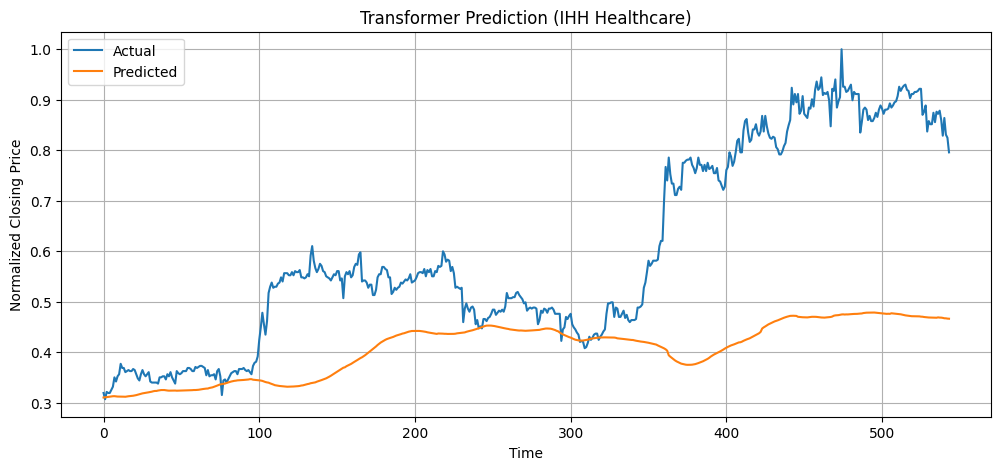

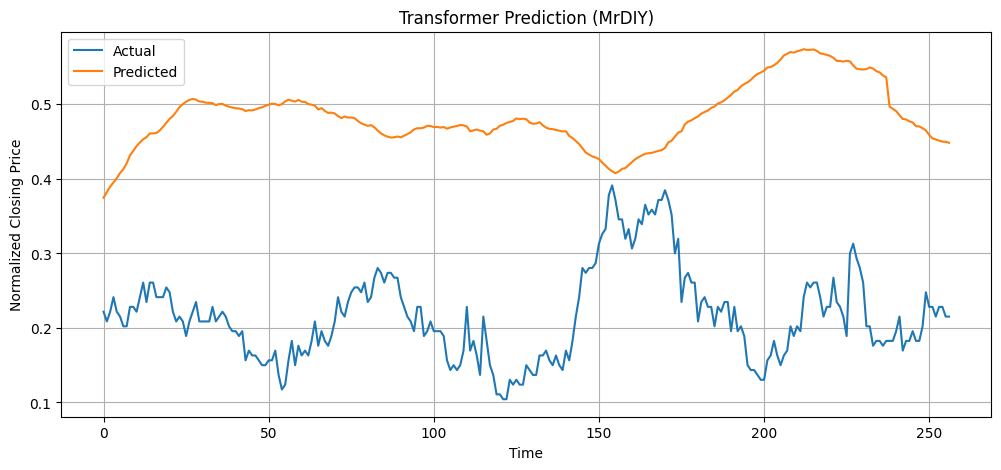

In [ ]:
for company in transformer_models.keys():

    plt.figure(figsize=(12,5))

    plt.plot(
        split_data[company]["y_test"],
        label="Actual"
    )

    plt.plot(
        transformer_predictions[company],
        label="Predicted"
    )

    plt.title(f"Transformer Prediction ({company})")

    plt.xlabel("Time")

    plt.ylabel("Normalized Closing Price")

    plt.legend()

    plt.grid(True)

    plt.show()

# Model Performance Comparison

## Display Overall Performance Table

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["Company","Model"]
)

results_df.reset_index(drop=True, inplace=True)

display(results_df)

,Company,Model,MAE,RMSE,MAPE,R2,DA
0,IHH Healthcare,GRU,0.012385,0.019218,2.070135,0.990114,40.699816
1,IHH Healthcare,LSTM,0.020927,0.030520,3.089039,0.975067,41.804788
2,IHH Healthcare,Transformer,0.189916,0.249289,26.606284,-0.663450,40.699816
3,Maybank,GRU,0.020021,0.027885,3.125835,0.938909,38.121547
4,Maybank,LSTM,0.018133,0.027890,2.689881,0.938885,36.464088
5,Maybank,Transformer,0.164572,0.198824,24.321295,-2.105843,41.620626
6,MrDIY,GRU,0.052788,0.061832,28.281352,-0.061318,42.187500
7,MrDIY,LSTM,0.055960,0.068332,30.280542,-0.296199,41.796875
8,MrDIY,Transformer,0.267619,0.280595,142.417546,-20.856321,41.796875
9,Petronas Gas,GRU,0.026725,0.035416,7.788903,0.648649,37.384899


## Export Results Table

In [ ]:
results_df.to_csv(
    "Model_Comparison_Results.csv",
    index=False
)

print("Comparison table exported successfully.")

Comparison table exported successfully.


## Compare MAE

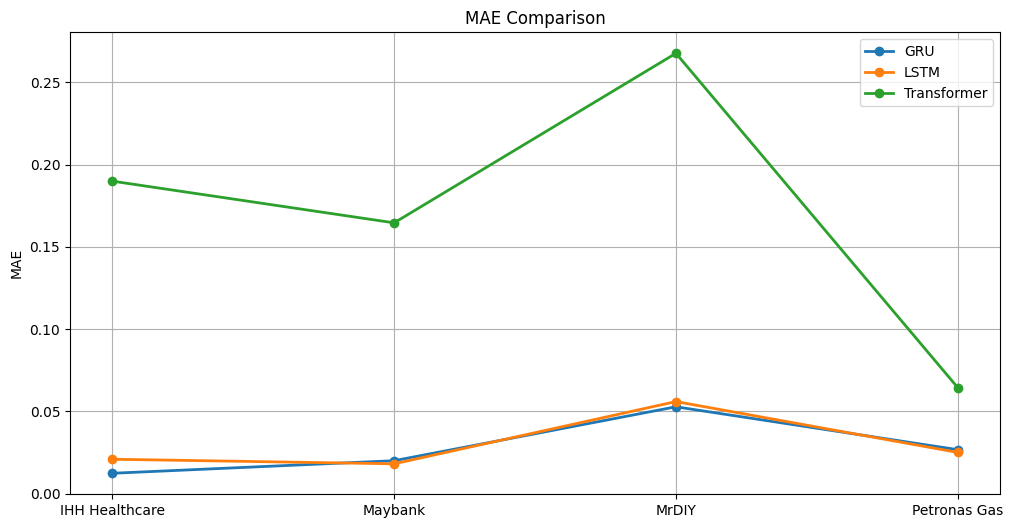

In [ ]:
plt.figure(figsize=(12,6))

for model in results_df["Model"].unique():

    subset = results_df[
        results_df["Model"]==model
    ]

    plt.plot(
        subset["Company"],
        subset["MAE"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.title("MAE Comparison")

plt.ylabel("MAE")

plt.grid(True)

plt.legend()

plt.show()

## Compare RMSE

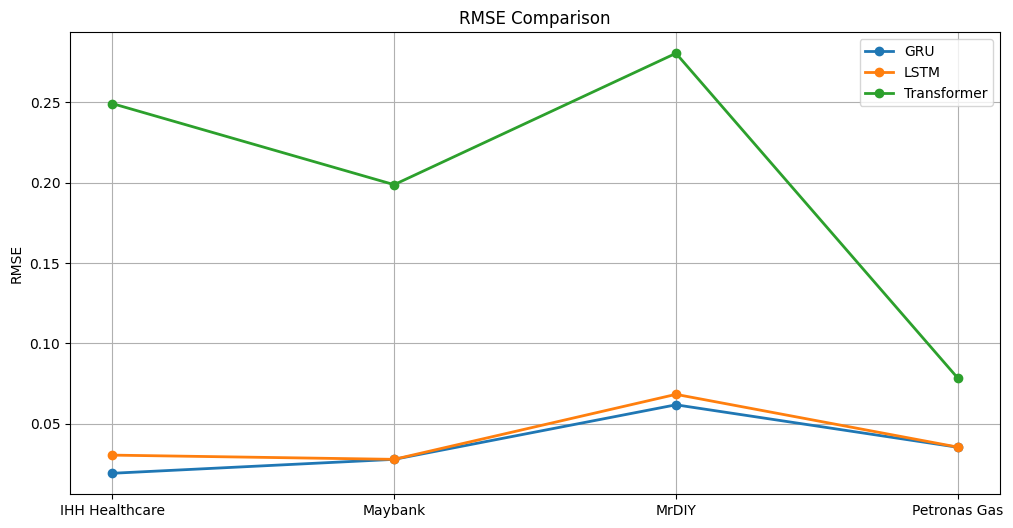

In [ ]:
plt.figure(figsize=(12,6))

for model in results_df["Model"].unique():

    subset = results_df[
        results_df["Model"]==model
    ]

    plt.plot(
        subset["Company"],
        subset["RMSE"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.title("RMSE Comparison")

plt.ylabel("RMSE")

plt.grid(True)

plt.legend()

plt.show()

## Compare MAPE

In [ ]:
plt.figure(figsize=(12,6))

for model in results_df["Model"].unique():

    subset = results_df[
        results_df["Model"]==model
    ]

    plt.plot(
        subset["Company"],
        subset["MAPE"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.title("MAPE Comparison")

plt.ylabel("MAPE")

plt.grid(True)

plt.legend()

plt.show()

## Compare R² Score

In [ ]:
plt.figure(figsize=(12,6))

for model in results_df["Model"].unique():

    subset = results_df[
        results_df["Model"]==model
    ]

    plt.plot(
        subset["Company"],
        subset["R2"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.title("R² Score Comparison")

plt.ylabel("R²")

plt.grid(True)

plt.legend()

plt.show()

## Compare Directional Accuracy

In [ ]:
plt.figure(figsize=(12,6))

for model in results_df["Model"].unique():

    subset = results_df[
        results_df["Model"]==model
    ]

    plt.plot(
        subset["Company"],
        subset["DA"],
        marker="o",
        linewidth=2,
        label=model
    )

plt.title("Directional Accuracy Comparison")

plt.ylabel("Directional Accuracy (%)")

plt.grid(True)

plt.legend()

plt.show()

## Best Performing Model

In [ ]:
print("Lowest MAE")
display(results_df.loc[[results_df["MAE"].idxmin()]])

print("Lowest RMSE")
display(results_df.loc[[results_df["RMSE"].idxmin()]])

print("Lowest MAPE")
display(results_df.loc[[results_df["MAPE"].idxmin()]])

print("Highest R²")
display(results_df.loc[[results_df["R2"].idxmax()]])

print("Highest Directional Accuracy")
display(results_df.loc[[results_df["DA"].idxmax()]])

# Market Regime Analysis

## Create Market Regime Labels

In [ ]:
def assign_market_regime(df):

    df = df.copy()

    difference = (df["Close"] - df["SMA50"]) / df["SMA50"]

    conditions = [

        difference > 0.02,

        difference < -0.02

    ]

    choices = [

        "Bull",

        "Bear"

    ]

    df["Market_Regime"] = np.select(
        conditions,
        choices,
        default="Sideways"
    )

    return df

## Apply the Regime Classification

In [ ]:
market_datasets = {}

for company, df in datasets.items():

    market_datasets[company] = assign_market_regime(df)

print("Market regimes assigned successfully.")

## Display Market Regime Counts

In [ ]:
for company, df in market_datasets.items():

    print("="*60)

    print(company)

    print("="*60)

    display(df["Market_Regime"].value_counts())

## Visualize Market Regimes

In [ ]:
for company, df in market_datasets.items():

    plt.figure(figsize=(14,5))

    plt.plot(
        df["Date"],
        df["Close"],
        label="Closing Price"
    )

    bull = df[df["Market_Regime"]=="Bull"]

    bear = df[df["Market_Regime"]=="Bear"]

    side = df[df["Market_Regime"]=="Sideways"]

    plt.scatter(
        bull["Date"],
        bull["Close"],
        s=8,
        label="Bull"
    )

    plt.scatter(
        bear["Date"],
        bear["Close"],
        s=8,
        label="Bear"
    )

    plt.scatter(
        side["Date"],
        side["Close"],
        s=8,
        label="Sideways"
    )

    plt.title(company)

    plt.legend()

    plt.grid(True)

    plt.show()

# Final Model Performance Summary

## Overall Performance Table

In [ ]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by=["Company", "Model"]
)

results_df.reset_index(drop=True, inplace=True)

display(results_df)

## Rank the Models

In [ ]:
ranking = results_df.copy()

ranking["Overall Rank"] = (
    ranking["RMSE"].rank(method="dense") +
    ranking["MAE"].rank(method="dense") +
    ranking["MAPE"].rank(method="dense") -
    ranking["R2"].rank(method="dense", ascending=False) -
    ranking["DA"].rank(method="dense", ascending=False)
)

ranking = ranking.sort_values("Overall Rank")

display(ranking)

## Average Performance of Each Model

In [ ]:
average_results = results_df.groupby("Model").mean(numeric_only=True)

display(average_results)

## Visual Comparison of RMSE

In [ ]:
plt.figure(figsize=(10,5))

average_results["RMSE"].plot(kind="bar")

plt.title("Average RMSE Comparison")

plt.ylabel("RMSE")

plt.grid(axis="y")

plt.show()

## Visual Comparison of MAE

In [ ]:
plt.figure(figsize=(10,5))

average_results["MAE"].plot(kind="bar")

plt.title("Average MAE Comparison")

plt.ylabel("MAE")

plt.grid(axis="y")

plt.show()

## Visual Comparison of R² Score

In [ ]:
plt.figure(figsize=(10,5))

average_results["R2"].plot(kind="bar")

plt.title("Average R² Score")

plt.ylabel("R²")

plt.grid(axis="y")

plt.show()

## Visual Comparison of Directional Accuracy

In [ ]:
plt.figure(figsize=(10,5))

average_results["DA"].plot(kind="bar")

plt.title("Average Directional Accuracy")

plt.ylabel("Accuracy (%)")

plt.grid(axis="y")

plt.show()

## Export the Results

In [ ]:
results_df.to_csv(
    "Final_Model_Results.csv",
    index=False
)

average_results.to_csv(
    "Average_Model_Results.csv"
)

ranking.to_csv(
    "Model_Ranking.csv",
    index=False
)

print("Results exported successfully!")

# FINAL OVERALL RESULTS

In [ ]:
import pandas as pd

# Calculate average performance of each model
overall_results = results_df.groupby("Model").agg({
    "MAE": "mean",
    "RMSE": "mean",
    "MAPE": "mean",
    "R2": "mean",
    "DA": "mean"
})

# Calculate an overall score
# Lower Score = Better Model
overall_results["Overall Score"] = (
    overall_results["MAE"].rank(ascending=True) +
    overall_results["RMSE"].rank(ascending=True) +
    overall_results["MAPE"].rank(ascending=True) +
    overall_results["R2"].rank(ascending=False) +
    overall_results["DA"].rank(ascending=False)
)

overall_results = overall_results.sort_values("Overall Score")

print("="*80)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("="*80)

display(overall_results)

# Identify the best model
best_model = overall_results.index[0]

print("\n" + "="*80)
print("🏆 OVERALL BEST MODEL")
print("="*80)

print(f"Best Performing Model : {best_model}")

print("\nAverage Performance")

display(overall_results.loc[[best_model]])

print("\nEvaluation Summary")
print(f"• Average MAE  : {overall_results.loc[best_model, 'MAE']:.6f}")
print(f"• Average RMSE : {overall_results.loc[best_model, 'RMSE']:.6f}")
print(f"• Average MAPE : {overall_results.loc[best_model, 'MAPE']:.2f}%")
print(f"• Average R²   : {overall_results.loc[best_model, 'R2']:.4f}")
print(f"• Average DA   : {overall_results.loc[best_model, 'DA']:.2f}%")

print("\nConclusion")
print(f"Based on the overall experimental results, {best_model} achieved the best prediction performance among the three deep learning models.")
print("The ranking is determined using the combined performance of MAE, RMSE, MAPE, R² Score, and Directional Accuracy.")

# Save the overall summary
overall_results.to_csv("Overall_Model_Performance.csv")

In [ ]:
print(len(results))

results_df = pd.DataFrame(results)

display(results_df)

# Conclusion

Based on the overall experimental results, **(replace with the model name shown above, e.g., GRU)** achieved the best overall performance among the three deep learning models evaluated in this study.

The comparison was conducted using MAE, RMSE, MAPE, R² Score, and Directional Accuracy across four Bursa Malaysia stocks. The selected model consistently demonstrated the best balance between prediction accuracy and forecasting capability under the experimental settings used.

Overall, this study shows that deep learning models are effective for Malaysian stock price prediction, while also highlighting that model performance may vary across different stocks and market conditions. Future work can extend this research by incorporating additional financial indicators, macroeconomic variables, sentiment analysis, and more advanced hybrid deep learning architectures.